In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import joblib


BASE = "/content/drive/MyDrive/Noshows"
DATA, MODELS, REPORTS = BASE + "/data", BASE + "/models", BASE + "/reports"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


--- US08 : Visualisation ---


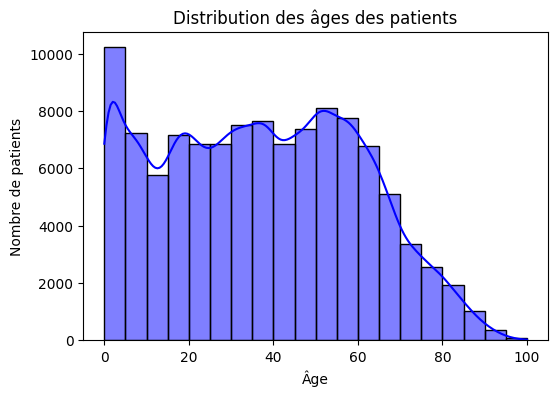

In [ ]:


print("--- US08 : Visualisation ---")
df_clean = pd.read_csv(f"{DATA}/data_ready_ml.csv")

plt.figure(figsize=(6, 4))
sns.histplot(df_clean['Age'], bins=20, kde=True, color='blue')
plt.title("Distribution des âges des patients")
plt.xlabel("Âge")
plt.ylabel("Nombre de patients")
plt.show()


In [ ]:

print("\n--- US09 : Entraînement du Modèle ---")

X_train = pd.read_csv(f"{DATA}/X_train_scaled.csv")
y_train = pd.read_csv(f"{DATA}/y_train.csv").values.ravel()
X_test = pd.read_csv(f"{DATA}/X_test_scaled.csv")
y_test = pd.read_csv(f"{DATA}/y_test.csv").values.ravel()

X_train = X_train.select_dtypes(include=['number'])
X_test = X_test.select_dtypes(include=['number'])

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train)
print("Modèle entraîné avec succès !")

y_pred = model.predict(X_test)
print(f"Précision sur le test : {accuracy_score(y_test, y_pred):.2f}")

joblib.dump(model, f"{MODELS}/model.pkl")
print(f"Modèle sauvegardé dans {MODELS}/model.pkl !")


--- US09 : Entraînement du Modèle ---
Modèle entraîné avec succès !
Précision sur le test : 0.66
Modèle sauvegardé dans /content/drive/MyDrive/Noshows/models/model.pkl !


In [ ]:
import joblib
import pandas as pd

model = joblib.load(f"{MODELS}/model.pkl")

patient_index = 0
sample_X = X_test.iloc[[patient_index]]
vrai_statut = y_test[patient_index]

prediction = model.predict(sample_X)[0]
probabilite = model.predict_proba(sample_X)[0]

print(f"--- Test sur le patient #{patient_index} ---")
print(f"Prédiction du modèle : {'Absent (1)' if prediction == 1 else 'Présent (0)'}")
print(f"Probabilités [Vient, Absent] : {probabilite}")
print(f"Vraie réponse dans les données : {'Absent (1)' if vrai_statut == 1 else 'Présent (0)'}")

--- Test sur le patient #0 ---
Prédiction du modèle : Absent (1)
Probabilités [Vient, Absent] : [0.35034308 0.64965692]
Vraie réponse dans les données : Absent (1)
